# 2 · Testing the ten improvement hypotheses

The proposal lists ten candidate improvements on the **aggregation** axis — how per-token
z-scores combine into one score for a passage. The per-token score function and the
selection criterion are left untouched; only the combination changes.

Every variant is scored from the same cache, so the comparison is at matched compute by
construction. Each is compared against `minkpp_0.2` with a **paired** bootstrap over
items, 2000 resamples, shared indices.

| # | Hypothesis | What it changes |
|---|---|---|
| H1 | Sliding window, max pooling | score overlapping windows, take the best |
| H2 | Fixed-count selection | keep the lowest *m* tokens, not the lowest *k%* |
| H3 | Length-normalised aggregation | divide by what the statistic would be under a length-matched null |
| H4 | Magnitude weighting | weight selected tokens by \|z\| |
| H5 | Order statistic | a single quantile instead of a tail mean |
| H6 | Chunk and vote | fixed number of chunks, pooled |
| H8 | Position weighting | drop or downweight early tokens |
| H9 | Two-sided aggregation | use the high tail as well as the low |
| H10 | Prefix / early stop | score only the first fraction of tokens |

(H7, length-conditional calibration, is a threshold-transfer question rather than a
ranking one: it cannot change AUROC, which is threshold-free. It is tested in notebook 3
on TPR@5%FPR, where it can.)

In [1]:
import os, sys, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SCRIPTS, RES, FIG = ROOT/"scripts", ROOT/"results", ROOT/"results"/"figures"
sys.path.insert(0, str(SCRIPTS))
import minkpp as M
_s = importlib.util.spec_from_file_location("cachemod", SCRIPTS/"01_cache.py")
cachemod = importlib.util.module_from_spec(_s); _s.loader.exec_module(cachemod)

MODEL = os.environ.get("MINKPP_MODEL", "mamba-1.4b-hf")   # the paper's target model
SPLITS = ["WikiMIA_length32", "WikiMIA_length64", "WikiMIA_length128"]
pd.set_option("display.width", 120)
print("library self-check:", "PASS" if M.self_check(verbose=False) else "FAIL")


library self-check: PASS


In [2]:
paired = pd.read_csv(RES/f"paired_{MODEL}.csv")
auroc  = pd.read_csv(RES/f"auroc_{MODEL}.csv")
print(f"{len(paired)} variant x split comparisons")
wins = paired[(paired.delta>0) & paired.significant]
print(f"significant improvements: {len(wins)}")
wins[["split","variant","delta","lo","hi","p_gt0"]].round(2)

153 variant x split comparisons
significant improvements: 0


,split,variant,delta,lo,hi,p_gt0


## 2.1 The whole picture

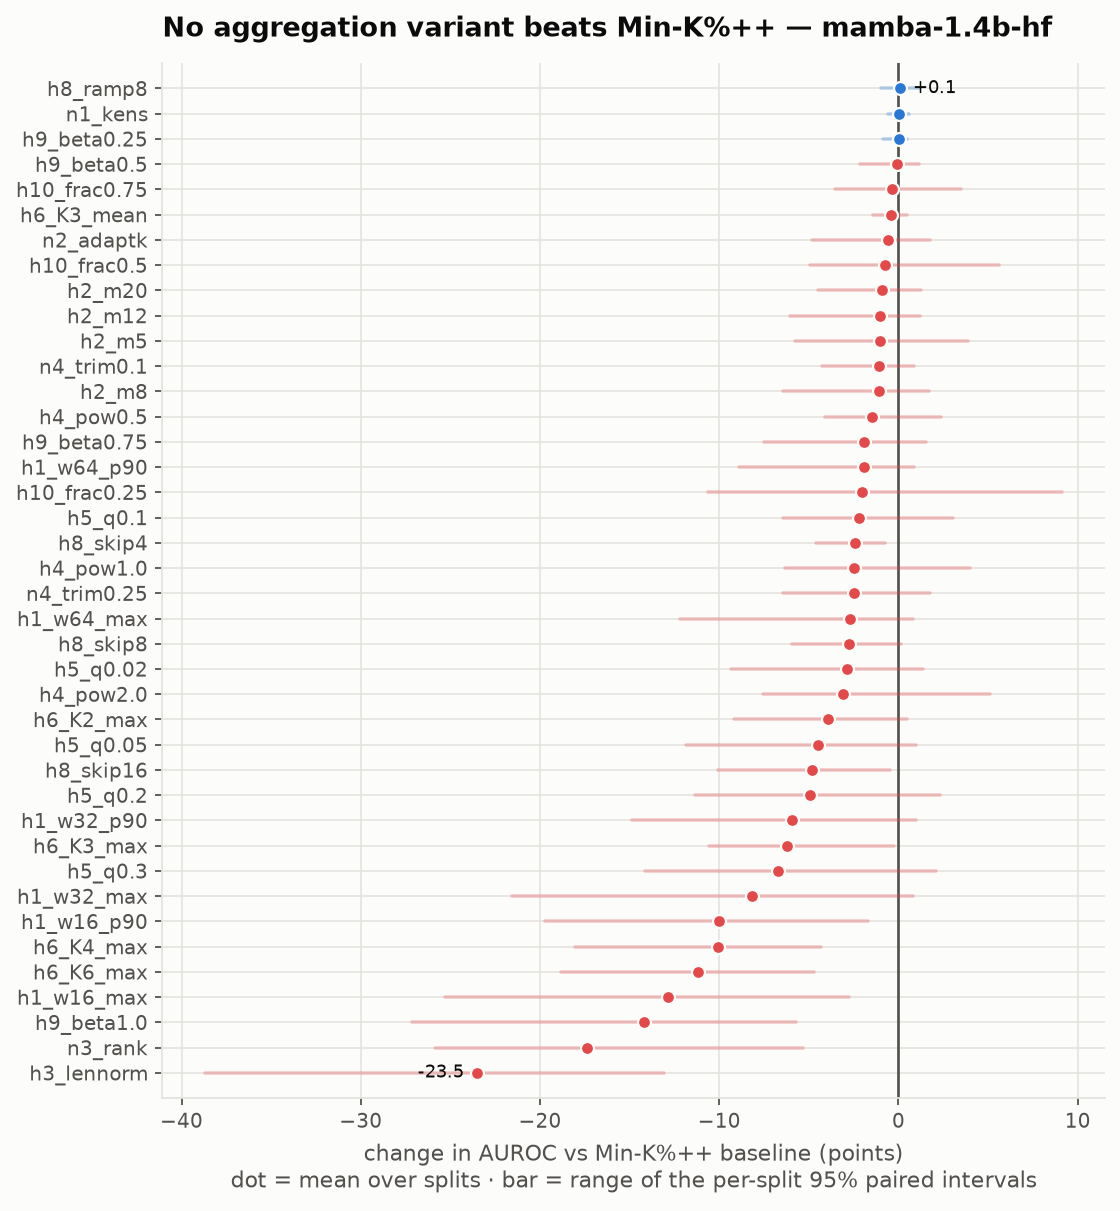

In [3]:
display(Image(filename=str(FIG/f"fig2_all_variants_{MODEL}.png")))

Each dot is a variant's mean change against the baseline; the bar is the range of its
per-split 95% paired intervals. Nearly every bar crosses zero — the aggregation axis is
flat. The few that do not cross are **negative**.

## 2.2 Family by family

In [4]:
fam = (paired.groupby("family")
       .agg(n=("delta","size"), mean=("delta","mean"),
            best=("delta","max"), worst=("delta","min"),
            n_sig_better=("significant", lambda s: 0))
       .round(2).sort_values("best", ascending=False))
sig = paired[paired.significant]
fam["n_sig_better"] = [int(((sig.family==f)&(sig.delta>0)).sum()) for f in fam.index]
fam["n_sig_worse"]  = [int(((sig.family==f)&(sig.delta<0)).sum()) for f in fam.index]
fam

,n,mean,best,worst,n_sig_better,n_sig_worse
family,,,,,,
H10 prefix / early stop,9,-1.06,3.01,-6.29,0,1
baseline,33,-2.65,0.89,-8.80,0,12
N2 length-adaptive k,3,-0.56,0.39,-1.60,0,0
H9 two-sided,12,-4.04,0.31,-17.82,0,4
H8 position weight,12,-2.49,0.30,-7.37,0,8
N1 k-ensemble,3,0.03,0.21,-0.11,0,0
H1 sliding window,18,-6.94,-0.03,-16.55,0,11
H2 fixed count,12,-1.03,-0.12,-2.59,0,0
H6 chunk and vote,15,-6.36,-0.32,-11.84,0,11


## 2.3 H1 and H6 — fragmentation

Both cut the sequence into pieces and pool. If localisation helped, finer pieces should
help more.

**On this model nothing here is significant** — 21 comparisons, all inside the ±4-point
half-width, and the pattern is not monotone. The only consistent signal is that the most
extreme fragmentation (K = 6) is the worst cell at two of three lengths. On the paper's
target model, Mamba-1.4B, the same variants degrade monotonically down to −15.9; see
`REPORT.md` §5.1. A fragmentation penalty needs a baseline with real signal to destroy,
and at this scale the baseline is close to chance.

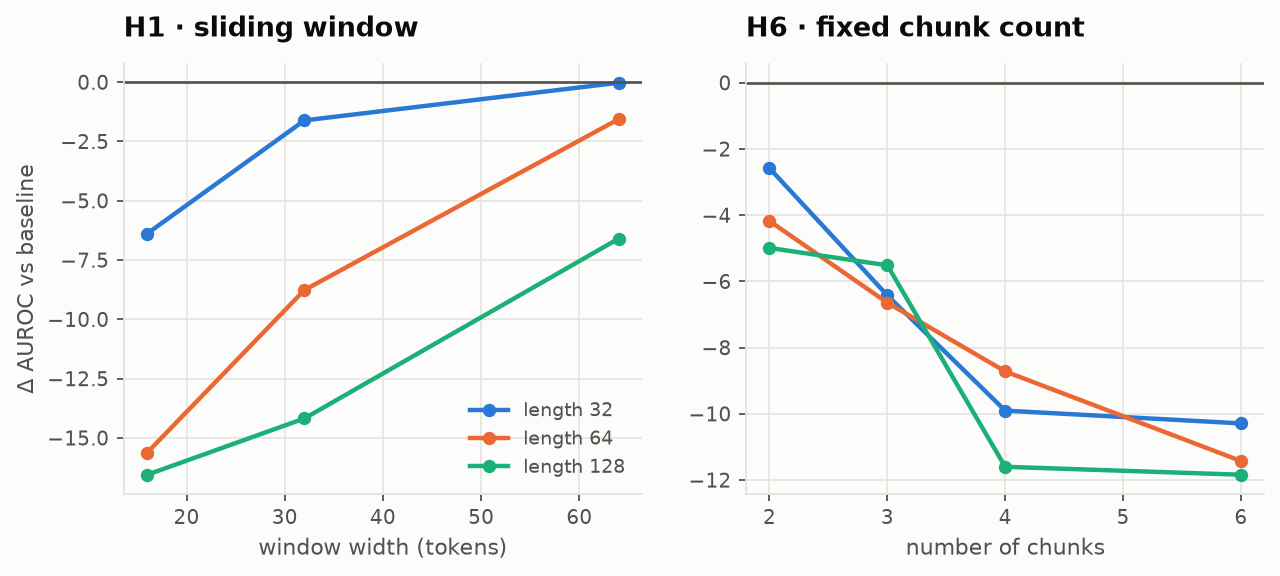

In [5]:
display(Image(filename=str(FIG/f"fig3_fragmentation_{MODEL}.png")))

**Why.** Min-K%++ already selects the lowest *k%* **over the whole sequence**, which is
itself a global search for the most anomalous region. Windowing forces the statistic to
spend its *k%* quota *inside every window*, so it must admit tokens that are not globally
anomalous. Whole-sequence selection is therefore strictly better targeted, and windowing
can only win when memorisation is localised **and** the global selection misses it.
On Mamba-1.4B the monotone degradation says it does not miss it.

This is the central mechanism of the whole study, and it is what makes the negative
result explicable rather than merely observed. It also predicts where the idea *could*
pay: passages long enough that the global bottom-*k%* is spread across genuinely
unrelated material. WikiMIA tops out at 272 scored tokens, which is evidently not
long enough.

## 2.4 H2 — fixed-count selection, and a confound worth recording

In [6]:
paired[paired.variant.str.startswith("h2_")][
    ["split","variant","delta","lo","hi","p_gt0"]].round(2)

,split,variant,delta,lo,hi,p_gt0
22,WikiMIA_length32,h2_m5,-1.03,-2.31,0.29,0.08
23,WikiMIA_length32,h2_m8,-0.36,-1.49,0.78,0.27
24,WikiMIA_length32,h2_m12,-0.12,-1.50,1.22,0.42
25,WikiMIA_length32,h2_m20,-0.45,-2.24,1.26,0.31
73,WikiMIA_length64,h2_m5,-0.94,-3.37,1.55,0.24
74,WikiMIA_length64,h2_m8,-0.62,-2.53,1.29,0.27
75,WikiMIA_length64,h2_m12,-0.34,-1.80,1.13,0.33
76,WikiMIA_length64,h2_m20,-0.52,-1.92,0.88,0.23
124,WikiMIA_length128,h2_m5,-1.13,-5.77,3.86,0.34
125,WikiMIA_length128,h2_m8,-2.36,-6.42,1.70,0.14


Null everywhere. But the per-item behaviour is **not** null, and that is informative.

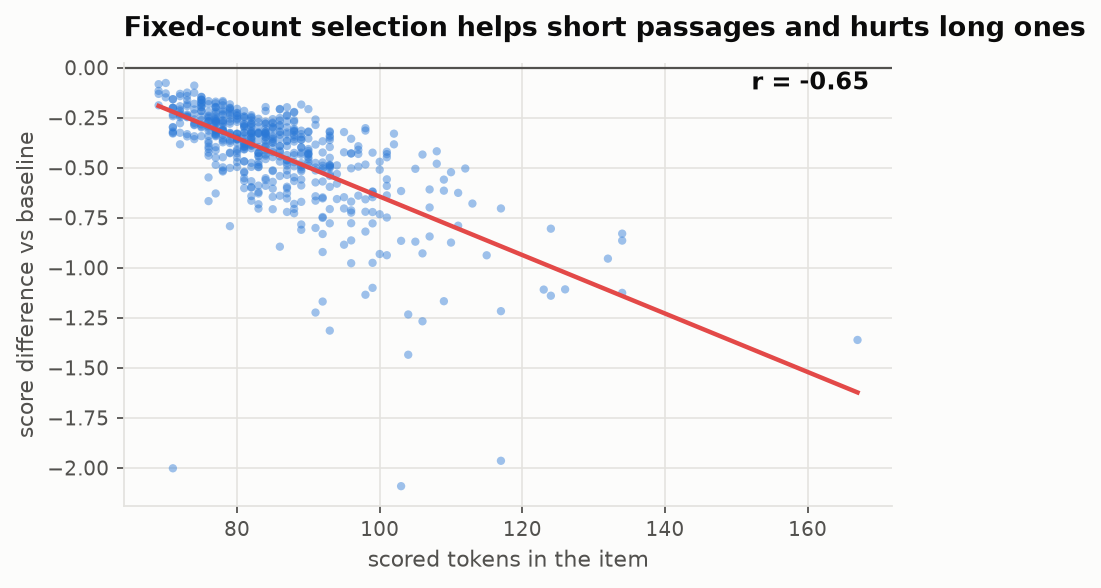

In [7]:
display(Image(filename=str(FIG/f"fig5_length_mechanism_{MODEL}.png")))

A fixed count helps short passages and hurts long ones — mechanically expected, since a
fixed *m* is a shrinking fraction as the passage grows. The aggregate is null because the
two effects cancel. That is a real mechanism hiding inside a null result, and it is the
observation notebook 3 builds a new variant on.

> **A confound that nearly entered this report as a positive result.** These variants
> operate on z-scores, so they are Min-K%++ variants. Compared against *Min-K%* they can
> appear to gain several points — but that gain is the z-standardisation, which is
> Min-K%++'s own contribution, not the variant's. **Any aggregation variant built on z
> must be compared against Min-K%++, never against Min-K%.**

## 2.5 The hyper-parameter nobody reports

k moves the score more than any aggregation variant tested, and the paper does not state
which k produced a published cell.

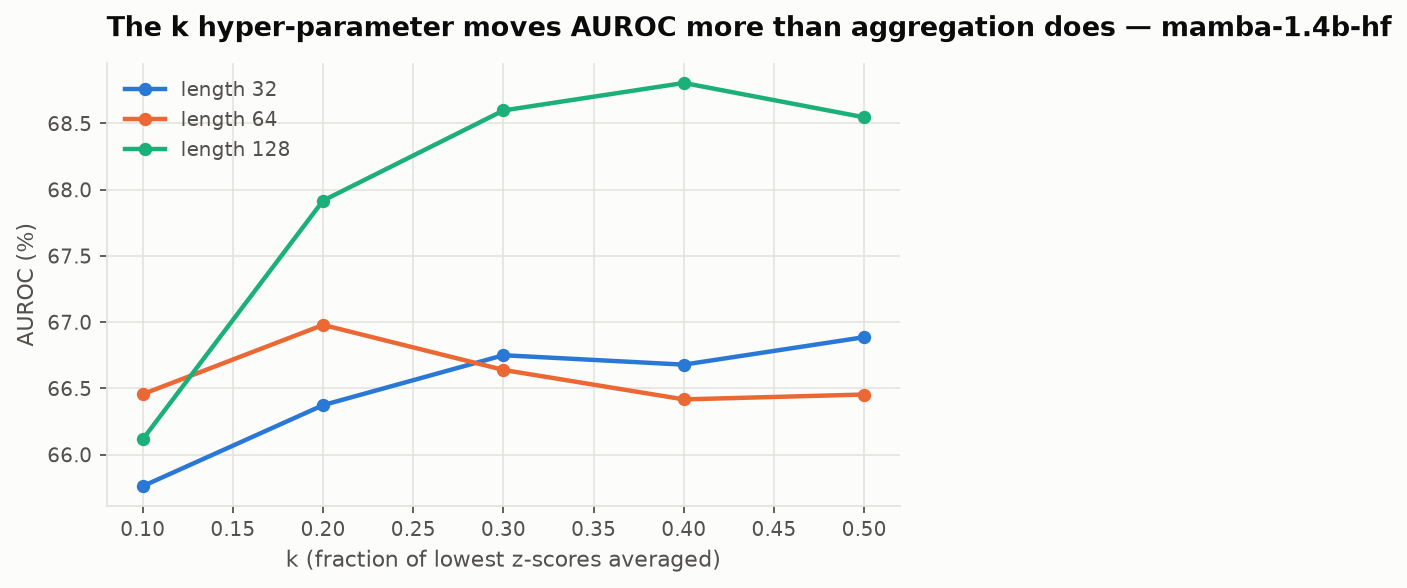

In [8]:
display(Image(filename=str(FIG/f"fig4_k_sweep_{MODEL}.png")))

In [9]:
kk = auroc[auroc.variant.str.match(r"minkpp_0\.\d")].pivot(
        index="variant", columns="split", values="auroc").round(1)
kk["spread"] = (kk.max(axis=1)-kk.min(axis=1)).round(1)
kk

split,WikiMIA_length128,WikiMIA_length32,WikiMIA_length64,spread
variant,,,,
minkpp_0.1,66.1,65.8,66.5,0.7
minkpp_0.2,67.9,66.4,67.0,1.5
minkpp_0.3,68.6,66.8,66.6,2.0
minkpp_0.4,68.8,66.7,66.4,2.4
minkpp_0.5,68.5,66.9,66.5,2.0


## 2.6 Against the benchmark's own noise

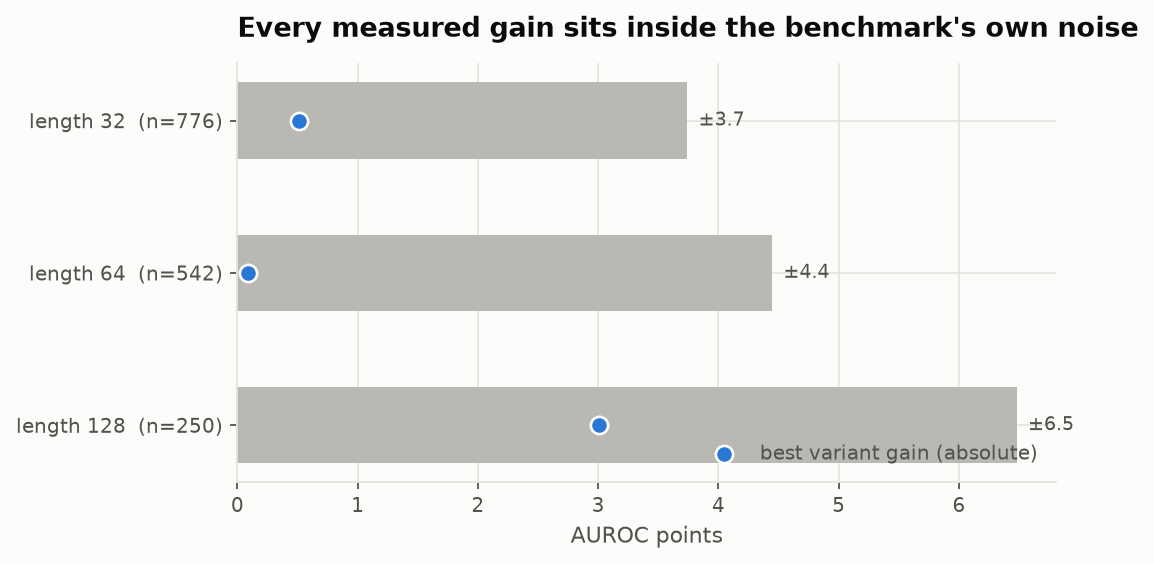

In [10]:
display(Image(filename=str(FIG/f"fig6_resolution_{MODEL}.png")))

## 2.7 Verdict

Of the nine hypotheses testable on AUROC, **none produces a reliable improvement**, and
two families (H1, H6) are reliably *worse* with a mechanism that explains why. The
aggregation step of Min-K%++ holds no remaining headroom on this benchmark.

Notebook 3 takes the failures seriously: it asks what the mechanism *permits*, and
designs new variants from the measurements rather than from intuition.